# **Healthcare Risk Classifier (Diabetes Prediction)**

# **Problem Statement**

Diabetes is a chronic disease that affects millions of people worldwide and can lead to severe health complications if not diagnosed early. Medical factors such as glucose level, Body Mass Index (BMI), age, blood pressure, and insulin levels play a crucial role in determining diabetes risk.

Manual diagnosis based only on observation may result in delayed or inaccurate decisions.

The objective of this project is to build a **classification-based Machine Learning model** to predict whether a patient may have diabetes using medical attributes and to identify the most important factors influencing diabetes risk.

# **Objectives of the Project**

* Understand patterns related to diabetes occurrence

* Perform basic data preprocessing

* Conduct minimal but meaningful Exploratory Data Analysis (EDA)

* Build classification-based machine learning models

* Evaluate model performance using classification metrics

* Identify key medical features influencing diabetes prediction

In [ ]:
#Uploading file
from google.colab import files
upload=files.upload()

Saving diabetes.csv to diabetes (1).csv


In [ ]:
#importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression,LinearRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report
from sklearn.preprocessing import StandardScaler,OneHotEncoder


In [ ]:
import pandas as pd
df=pd.read_csv("diabetes.csv")

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Diabetes Outcome Disrtibution

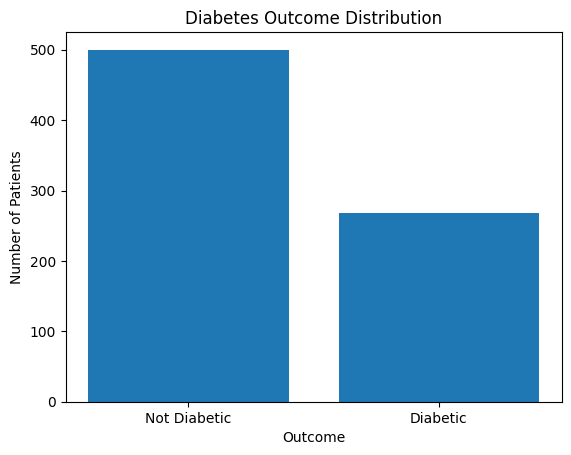

In [ ]:
import matplotlib.pyplot as plt

# Count outcome values
outcome_counts = df['Outcome'].value_counts()

# Plot
plt.figure("Red")
plt.bar(
    ['Not Diabetic', 'Diabetic'],
    outcome_counts.sort_index()
)
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")
plt.title("Diabetes Outcome Distribution")
plt.show()


Glucose vs Outcome

/tmp/ipython-input-3802217967.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


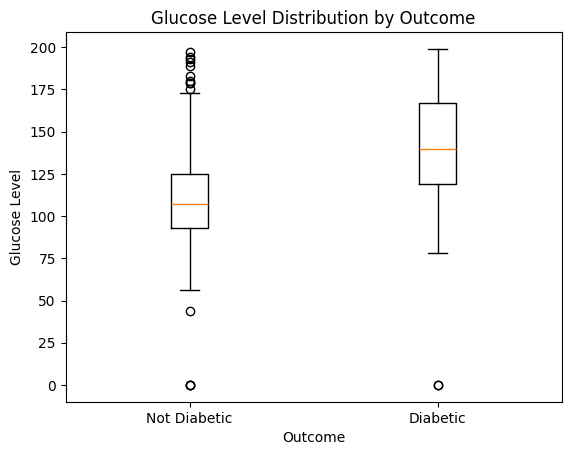

In [ ]:
import matplotlib.pyplot as plt

# Separate glucose values by outcome
glucose_no_diabetes = df[df['Outcome'] == 0]['Glucose']
glucose_diabetes = df[df['Outcome'] == 1]['Glucose']

# Box plot
plt.figure()
plt.boxplot(
    [glucose_no_diabetes, glucose_diabetes],
    labels=['Not Diabetic', 'Diabetic']
)
plt.xlabel("Outcome")
plt.ylabel("Glucose Level")
plt.title("Glucose Level Distribution by Outcome")
plt.show()


BMI vs Outcome

/tmp/ipython-input-3592518506.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


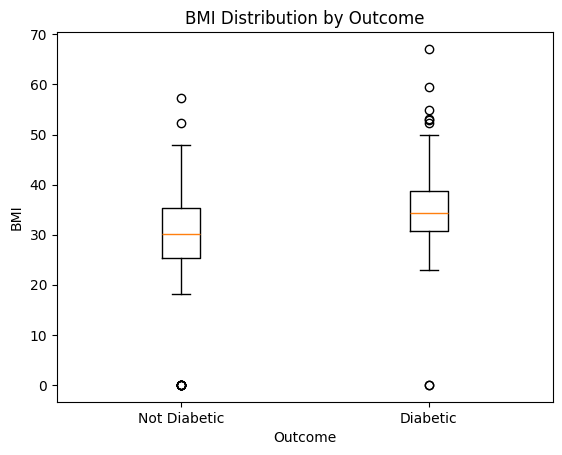

In [ ]:
import matplotlib.pyplot as plt

# Separate BMI values by outcome
bmi_no_diabetes = df[df['Outcome'] == 0]['BMI']
bmi_diabetes = df[df['Outcome'] == 1]['BMI']

# Box plot
plt.figure()
plt.boxplot(
    [bmi_no_diabetes, bmi_diabetes],
    labels=['Not Diabetic', 'Diabetic']
)
plt.xlabel("Outcome")
plt.ylabel("BMI")
plt.title("BMI Distribution by Outcome")
plt.show()

Age vs Outcome

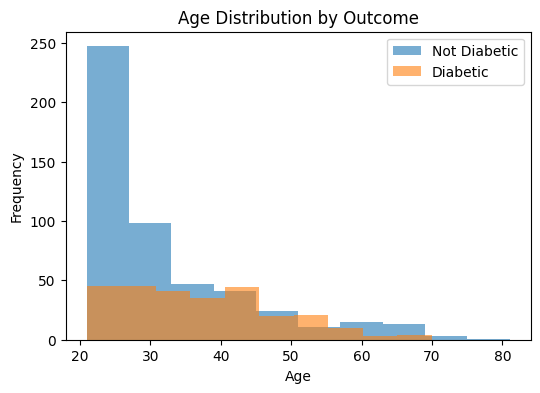

In [ ]:
import matplotlib.pyplot as plt

# Separate age values by outcome
age_no_diabetes = df[df['Outcome'] == 0]['Age']
age_diabetes = df[df['Outcome'] == 1]['Age']

# Histogram
plt.figure(figsize=(6,4))
plt.hist(age_no_diabetes, alpha=0.6, label='Not Diabetic')
plt.hist(age_diabetes, alpha=0.6, label='Diabetic')

plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Age Distribution by Outcome")
plt.legend()
plt.show()

Data Cleaning

In [ ]:
df.isnull().sum()

df.info()
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [ ]:

# Replace zeros with median
cols_with_zero_issue = ['Glucose', 'BMI', 'BloodPressure','Insulin',]
for col in cols_with_zero_issue:
    median_val = df[df[col] != 0][col].median()
    df[col] = df[col].replace(0, median_val)


print(df.isnull().sum())
print((df[cols_with_zero_issue] == 0).sum())


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Glucose          0
BMI              0
BloodPressure    0
Insulin          0
dtype: int64


In [ ]:
# Select numerical features
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
if 'Outcome' in num_cols:
    num_cols.remove('Outcome')


Feature and Target and Train-Test

In [ ]:

X = df.drop('Outcome', axis=1)
y = df['Outcome']


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


Training Decicsion Tree mode

In [ ]:

from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, num_cols),
])

dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=6, min_samples_split=10, random_state=42
    ))
])

dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))



Decision Tree Accuracy: 0.7467532467532467


Train Random Forest Model

In [ ]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200, max_depth=8, random_state=42, n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))


Random Forest Accuracy: 0.7532467532467533


Training Logistic Regression Model

In [ ]:

log_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42))
])


log_model.fit(X_train, y_train)
y_pred_log = log_model.predict(X_test)


print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_log))


Logistic Regression Accuracy: 0.7142857142857143


In [ ]:

def evaluate_model(y_test, y_pred):
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1-score:", f1_score(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

print("Logistic Regression")
evaluate_model(y_test, y_pred_log)

print("\nDecision Tree")
evaluate_model(y_test, y_pred_dt)

print("\nRandom Forest")
evaluate_model(y_test, y_pred_rf)


rf_classifier_model = rf_model.named_steps['classifier']

feature_names = rf_model.named_steps['preprocessor'].get_feature_names_out()

importances = rf_classifier_model.feature_importances_


Logistic Regression
Accuracy: 0.7142857142857143
Precision: 0.6136363636363636
Recall: 0.5
F1-score: 0.5510204081632653
Confusion Matrix:
 [[83 17]
 [27 27]]

Decision Tree
Accuracy: 0.7467532467532467
Precision: 0.7142857142857143
Recall: 0.46296296296296297
F1-score: 0.5617977528089888
Confusion Matrix:
 [[90 10]
 [29 25]]

Random Forest
Accuracy: 0.7532467532467533
Precision: 0.6666666666666666
Recall: 0.5925925925925926
F1-score: 0.6274509803921569
Confusion Matrix:
 [[84 16]
 [22 32]]


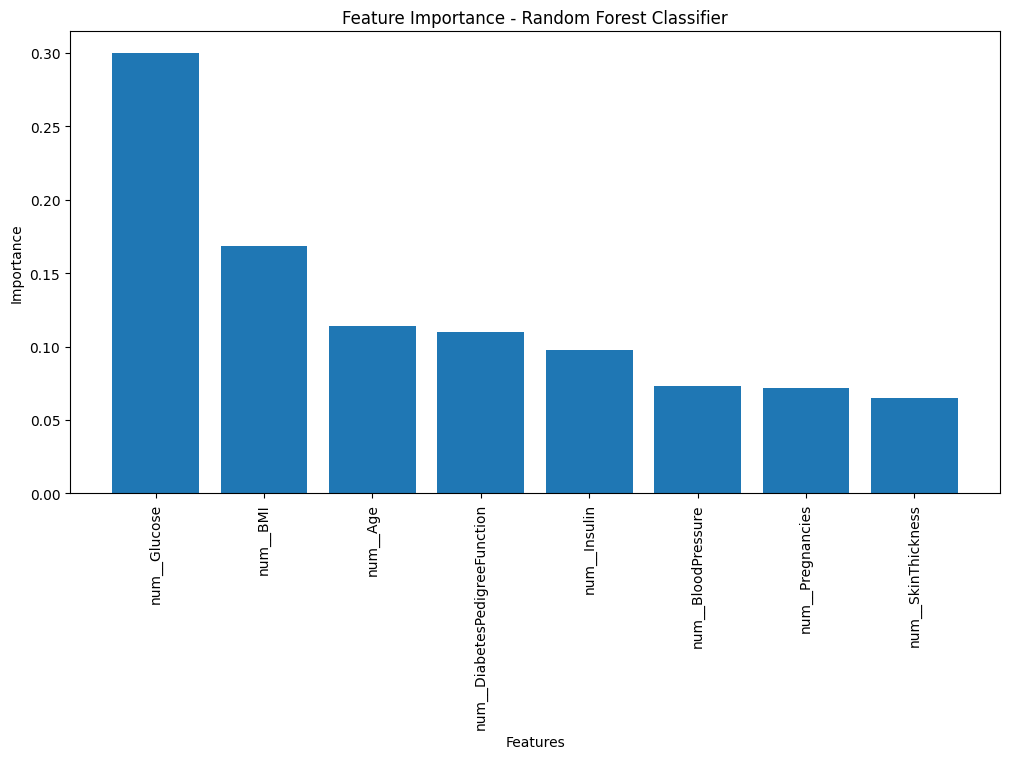

In [ ]:
# 4. Create DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12,6))
plt.bar(feature_importance_df['Feature'], feature_importance_df['Importance'])
plt.xticks(rotation=90)
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance - Random Forest Classifier")
plt.show()


Confusuin Matrix

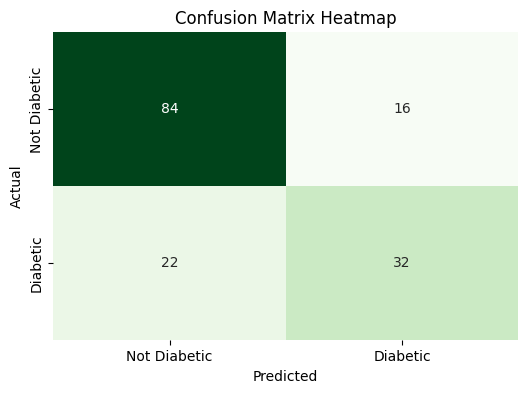

In [ ]:




import seaborn as sns
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Not Diabetic', 'Diabetic'],
            yticklabels=['Not Diabetic', 'Diabetic'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix Heatmap')
plt.show()